# ISIC 2018 skin-lesion classification with ResNet-50

This notebook trains one ResNet-50 on seven diagnosis classes. The saved outputs are from a complete 100-epoch run on an Apple M2 Pro using TensorFlow Metal on 26 October 2026. The best validation checkpoint was restored before testing: epoch 47, validation accuracy 83.42%, test accuracy 83.58% on 1,510 images.

To rerun in Colab, select a GPU runtime and execute the cells in order. A local TensorFlow GPU environment with Metal or CUDA is also supported. Each full run starts from ImageNet weights and trains for **100 epochs**. The first download is approximately 2.77 GB; later runs can reuse the data. Results may vary across devices and software versions. The analysis below describes the saved run.

By default, data are stored in `data/isic2018` and results in `results`, relative to the working directory. Set `ISIC_DATA_ROOT` or `ISIC_OUTPUT_ROOT` to use other locations.

In [ ]:
import setuptools
import os, json, time, math, zipfile
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED, IMG_SIZE, BATCH_SIZE, EPOCHS, HEAD_EPOCHS = 42, 224, 32, 100, 3
CLASS_NAMES = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']
DATA_ROOT = Path(os.environ.get('ISIC_DATA_ROOT', Path.cwd() / 'data' / 'isic2018')).expanduser().resolve()
OUT_DIR = Path(os.environ.get('ISIC_OUTPUT_ROOT', Path.cwd() / 'results')).expanduser().resolve()
DATA_ROOT.mkdir(parents=True, exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy('float32')
assert tf.config.list_physical_devices('GPU'), 'No TensorFlow GPU is available. Enable Metal or CUDA support before training.'
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| epochs', EPOCHS)
config = {'architecture': 'Keras ResNet50', 'initial_weights': 'ImageNet', 'epochs': EPOCHS,
    'head_epochs': HEAD_EPOCHS, 'fine_tune_epochs': EPOCHS-HEAD_EPOCHS, 'image_size': IMG_SIZE,
    'batch_size': BATCH_SIZE, 'seed': SEED, 'precision': 'float32', 'class_order': CLASS_NAMES,
    'optimizer': 'Adam', 'head_lr': 1e-3, 'fine_tune_lr': [3e-5, 1e-6], 'dropout': .3,
    'loss': 'ordinary categorical cross-entropy', 'fine_tune_layers': 'conv4/conv5, BatchNorm frozen',
    'selection': 'highest validation accuracy; first epoch on exact tie', 'test_previously_inspected': True}
(OUT_DIR / 'experiment_config.json').write_text(json.dumps(config, indent=2))
(OUT_DIR / 'environment.json').write_text(json.dumps({'tensorflow': tf.__version__, 'keras': keras.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__}, indent=2))

TensorFlow 2.18.1 | Keras 3.8.0 | epochs 100


90

## Data and labels

Download the images, diagnosis labels and lesion identifiers from the same official release. Labels are one-hot encoded in the fixed order `MEL, NV, BCC, AKIEC, BKL, DF, VASC`.

In [ ]:
BASE_URL = 'https://isic-archive.s3.amazonaws.com/challenges/2018/'
def download(name):
    path = DATA_ROOT / name
    def valid(candidate):
        try:
            if candidate.suffix == '.zip':
                with zipfile.ZipFile(candidate) as archive: return archive.testzip() is None
            table = pd.read_csv(candidate)
            return len(table) == 10015 and {'image', 'lesion_id'}.issubset(table.columns)
        except (OSError, ValueError, zipfile.BadZipFile, pd.errors.ParserError): return False
    if path.exists() and valid(path): return path
    partial = path.with_name('partial_' + name)
    for attempt in range(3):
        try:
            print('Downloading', name, flush=True)
            with requests.get(BASE_URL + name, stream=True, timeout=(20, 120)) as response:
                response.raise_for_status()
                with partial.open('wb') as handle:
                    for chunk in response.iter_content(1024 * 1024):
                        if chunk: handle.write(chunk)
            if not valid(partial): raise ValueError('Downloaded file failed validation: ' + name)
            partial.replace(path)
            return path
        except (requests.RequestException, OSError, ValueError, zipfile.BadZipFile):
            if attempt == 2: raise
            time.sleep(2)

def extract(path):
    with zipfile.ZipFile(path) as archive:
        assert all((DATA_ROOT / name).resolve().is_relative_to(DATA_ROOT.resolve()) for name in archive.namelist())
        archive.extractall(DATA_ROOT)

extract(download('ISIC2018_Task3_Training_GroundTruth.zip'))
labels = pd.read_csv(DATA_ROOT / 'ISIC2018_Task3_Training_GroundTruth' / 'ISIC2018_Task3_Training_GroundTruth.csv')
groups = pd.read_csv(download('ISIC2018_Task3_Training_LesionGroupings.csv'))
assert len(labels) == len(groups) == 10015 and labels.image.is_unique and groups.image.is_unique
one_hot = labels[CLASS_NAMES].to_numpy()
assert np.isin(one_hot, [0, 1]).all() and (one_hot.sum(axis=1) == 1).all()
metadata = labels.merge(groups[['image', 'lesion_id']], on='image', validate='one_to_one')
metadata['label'] = metadata[CLASS_NAMES].to_numpy().argmax(axis=1)
image_dir = DATA_ROOT / 'ISIC2018_Task3_Training_Input'
metadata['filepath'] = metadata.image.map(lambda name: str(image_dir / (name + '.jpg')))
metadata = metadata[['image', 'filepath', 'label', 'lesion_id']]
assert len(metadata) == 10015 and metadata.lesion_id.nunique() == 7470
assert metadata.groupby('lesion_id').label.nunique().max() == 1 and not metadata.isna().any().any()
assert metadata.label.value_counts().sort_index().tolist() == [1113, 6705, 514, 327, 1099, 115, 142]
if not all(Path(p).is_file() and Path(p).stat().st_size > 0 for p in metadata.filepath):
    extract(download('ISIC2018_Task3_Training_Input.zip'))
assert all(Path(p).is_file() and Path(p).stat().st_size > 0 for p in metadata.filepath)
display(labels[['image'] + CLASS_NAMES].head())

,image,MEL,NV,BCC,AKIEC,BKL,DF,VASC
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## Lesion-disjoint split

Use seed 42 to split unique lesions into approximately 70% training, 15% validation and 15% test, stratified by diagnosis. All views of one lesion stay together. This reproduces the existing split: **7,015 training, 1,490 validation and 1,510 test images**.

The split is lesion-disjoint, not verified patient-disjoint. It is an internal holdout from the official training collection, not the challenge test set. This holdout has been examined in earlier experiments; the new run still uses validation data alone to select weights. [ISIC lesion-grouping explanation](https://forum.isic-archive.com/t/task-3-supplemental-information/430).

,train,validation,test
MEL,789,164,160
NV,4695,1002,1008
BCC,369,73,72
AKIEC,229,46,52
BKL,748,168,183
DF,80,17,18
VASC,105,20,17


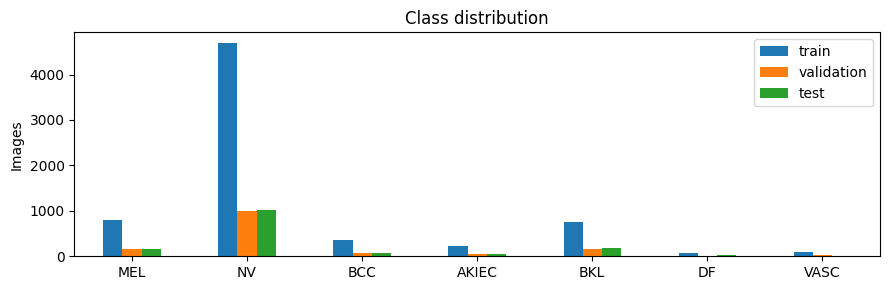

In [ ]:
lesions = metadata[['lesion_id', 'label']].drop_duplicates().sort_values('lesion_id')
trainval_ids, test_ids = train_test_split(lesions, test_size=.15, stratify=lesions.label, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=.15/.85, stratify=trainval_ids.label, random_state=SEED)
train_df, val_df, test_df = [metadata[metadata.lesion_id.isin(ids.lesion_id)].reset_index(drop=True)
                            for ids in [train_ids, val_ids, test_ids]]
partitions = {'train': train_df, 'validation': val_df, 'test': test_df}
assert [len(frame) for frame in partitions.values()] == [7015, 1490, 1510]
assert [frame.lesion_id.nunique() for frame in partitions.values()] == [5228, 1121, 1121]
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a.lesion_id).isdisjoint(b.lesion_id) and set(a.image).isdisjoint(b.image)
assert all(set(frame.label) == set(range(7)) for frame in partitions.values())
manifest = pd.concat([frame.assign(split=name) for name, frame in partitions.items()], ignore_index=True)
manifest.to_csv(OUT_DIR / 'split_manifest.csv', index=False)
(OUT_DIR / 'class_mapping.json').write_text(json.dumps({'class_order': CLASS_NAMES}, indent=2))
(OUT_DIR / 'data_provenance.json').write_text(json.dumps({'dataset': 'ISIC2018 Task3 / HAM10000',
    'source': BASE_URL, 'license': 'CC BY-NC 4.0', 'seed': SEED, 'split_unit': 'lesion_id',
    'source_correction': 'Official Task3 classification replaces the assigned Kaggle Task1 segmentation mirror'}, indent=2))
counts = pd.DataFrame({name: frame.label.value_counts().reindex(range(7)) for name, frame in partitions.items()})
counts.index = CLASS_NAMES
display(counts)
counts.plot.bar(figsize=(9, 3), rot=0, ylabel='Images', title='Class distribution'); plt.tight_layout(); plt.show()

## Image batches and augmentation

Resize the full RGB image to 224×224 with TensorFlow bilinear interpolation and antialiasing, then cache it as uint8 to limit memory use. Training-only flips and small rotations vary orientation while preserving the diagnosis label. This can reduce sensitivity and prediction variance caused by irrelevant orientation changes. Validation and test inputs are unchanged. The examples below check batch shapes, labels and augmentation.

2026-10-26 18:24:25.382998: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2026-10-26 18:24:25.383036: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-26 18:24:25.383051: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
I0000 00:00:1793010265.383306 35666649 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793010265.383532 35666649 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


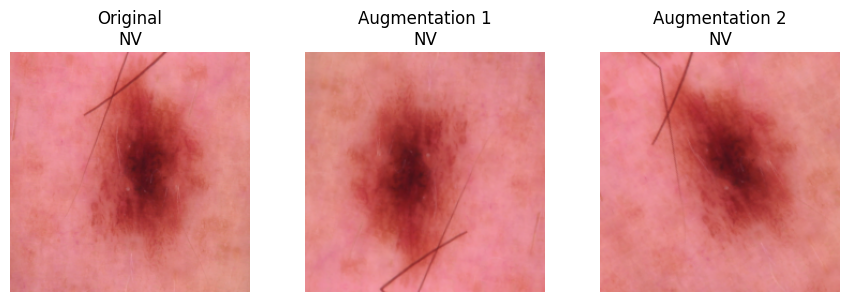

Batch: (32, 224, 224, 3) <dtype: 'uint8'> | labels: (32, 7)


In [ ]:
def read_image(filepath):
    image = tf.io.decode_jpeg(tf.io.read_file(filepath), channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method='bilinear', antialias=True)
    return tf.cast(image, tf.uint8)

def make_ds(frame, training=False):
    targets = np.eye(7, dtype=np.float32)[frame.label.to_numpy(dtype=int)]
    ds = tf.data.Dataset.from_tensor_slices((frame.filepath.tolist(), targets))
    ds = ds.map(lambda path, label: (read_image(path), label), num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training: ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(train_df, True), make_ds(val_df)
sample_images = tf.stack([read_image(path) for path in train_df.filepath.iloc[:BATCH_SIZE]])
sample_labels = tf.one_hot(train_df.label.iloc[:BATCH_SIZE].to_numpy(), depth=7)
assert sample_images.shape[1:] == (224, 224, 3) and sample_labels.shape[1] == 7
np.testing.assert_array_equal(sample_labels.numpy().argmax(axis=1), train_df.label.iloc[:len(sample_labels)])
augmentation = keras.Sequential([keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    keras.layers.RandomRotation(.1, seed=SEED + 1)], name='augmentation')
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for i, ax in enumerate(axes):
    image = sample_images[:1] if i == 0 else augmentation(sample_images[:1], training=True)
    ax.imshow(np.clip(image.numpy()[0], 0, 255).astype(np.uint8)); ax.axis('off')
    ax.set_title(('Original' if i == 0 else f'Augmentation {i}') + '\n' + CLASS_NAMES[int(train_df.iloc[0].label)])
plt.tight_layout(); plt.show()
print('Batch:', sample_images.shape, sample_images.dtype, '| labels:', sample_labels.shape)

## ResNet-50 and transfer learning

Start with ImageNet weights and a new seven-class softmax head. Train the head for 3 epochs with Adam at 1e-3, then fine-tune `conv4` and `conv5` for 97 epochs. Earlier layers and all BatchNorm parameters stay frozen. Fine-tuning uses a cosine learning rate from 3e-5 to 1e-6. The loss is ordinary categorical cross-entropy; dropout is 0.3. [Keras ResNet](https://keras.io/api/applications/resnet/), [Keras transfer learning](https://keras.io/guides/transfer_learning/).

`GradientTape` records operations for reverse-mode differentiation. Training stores activations, gradients and Adam's first/second gradient moments; inference does not need a backward graph. `training=False` controls dropout and BatchNorm but does not itself disable a surrounding tape. The small-batch check computes real gradients without updating weights. Adam averages gradients to estimate an update direction and squared gradients to scale each parameter's update. Bias correction accounts for their zero initialization; the learning-rate schedule controls the overall step size. [Adam](https://arxiv.org/abs/1412.6980).

In [ ]:
backbone = keras.applications.ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
backbone.trainable = False
inputs = keras.Input((224, 224, 3), dtype='float32', name='rgb_image')
x = augmentation(inputs)
x = keras.layers.Lambda(keras.applications.resnet50.preprocess_input, dtype='float32', name='imagenet_preprocessing')(x)
x = backbone(x, training=False)
x = keras.layers.GlobalAveragePooling2D(name='global_average_pool')(x)
x = keras.layers.Dropout(.3, name='classifier_dropout')(x)
outputs = keras.layers.Dense(7, activation='softmax', dtype='float32', name='predictions')(x)
model = keras.Model(inputs, outputs, name='ISIC2018_ResNet50')
loss_fn = keras.losses.CategoricalCrossentropy(from_logits=False)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=['accuracy'], jit_compile=False)
model.summary()
with (OUT_DIR / 'model_summary.txt').open('w') as handle:
    model.summary(expand_nested=True, print_fn=lambda line, **kwargs: handle.write(line + '\n'))
with tf.GradientTape() as tape:
    sample_probabilities = model(sample_images[:2], training=True)
    sample_loss = loss_fn(sample_labels[:2], sample_probabilities)
gradients = tape.gradient(sample_loss, model.trainable_variables)
assert sample_probabilities.shape == (2, 7) and np.isfinite(sample_probabilities.numpy()).all()
np.testing.assert_allclose(sample_probabilities.numpy().sum(axis=1), 1, atol=1e-5)
print('Small-batch loss:', float(sample_loss), '| gradient norm:', float(tf.linalg.global_norm(gradients)))

Model: "ISIC2018_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagenet_preprocessing (Lambda) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Small-batch loss: 2.643369197845459 | gradient norm: 45.09333419799805


## Training for 100 epochs

The same checkpoint callback is used in both phases. It saves the highest validation accuracy and retains the first epoch on an exact tie. All 100 epochs run; the test set does not select weights. Each progress line shows the time, duration and losses for one epoch. To start a new experiment, restart the session and run all cells; rerunning only this training cell continues the current model weights.

In [ ]:
checkpoint_path = OUT_DIR / 'best_model.weights.h5'
checkpoint = keras.callbacks.ModelCheckpoint(str(checkpoint_path), monitor='val_accuracy', mode='max',
    save_best_only=True, save_weights_only=True, verbose=0)
records, epoch_timer = [], {}
def record_epoch(epoch, logs):
    row = dict(logs)
    row.update(epoch=epoch + 1, phase='head' if epoch < HEAD_EPOCHS else 'fine_tune',
               learning_rate=float(keras.backend.get_value(model.optimizer.learning_rate)),
               seconds=time.time() - epoch_timer['start'])
    records.append(row)
    pd.DataFrame(records).to_csv(OUT_DIR / 'training_history.csv', index=False)
    print(f'{time.strftime("%H:%M:%S")} Epoch {epoch+1}/{EPOCHS} ({row["seconds"]:.0f}s): '
          f'loss={logs["loss"]:.4f}, accuracy={logs["accuracy"]:.4f}, '
          f'val_loss={logs["val_loss"]:.4f}, val_accuracy={logs["val_accuracy"]:.4f}', flush=True)
progress = keras.callbacks.LambdaCallback(on_epoch_begin=lambda epoch, logs: epoch_timer.update(start=time.time()),
                                         on_epoch_end=record_epoch)
model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=[checkpoint, progress], verbose=0)
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = layer.name.startswith(('conv4_', 'conv5_')) and not isinstance(layer, keras.layers.BatchNormalization)
model.compile(optimizer=keras.optimizers.Adam(3e-5), loss=loss_fn, metrics=['accuracy'], jit_compile=False)
with (OUT_DIR / 'model_summary_fine_tuning.txt').open('w') as handle:
    model.summary(expand_nested=True, print_fn=lambda line, **kwargs: handle.write(line + '\n'))
def learning_rate(epoch, current):
    position = (epoch - HEAD_EPOCHS) / (EPOCHS - HEAD_EPOCHS - 1)
    return 1e-6 + .5 * (3e-5 - 1e-6) * (1 + math.cos(math.pi * position))
schedule = keras.callbacks.LearningRateScheduler(learning_rate)
model.fit(train_ds, validation_data=val_ds, initial_epoch=HEAD_EPOCHS, epochs=EPOCHS,
          callbacks=[schedule, checkpoint, progress], verbose=0)
history = pd.DataFrame(records)
assert history.epoch.tolist() == list(range(1, EPOCHS + 1))
assert np.isfinite(history[['loss', 'accuracy', 'val_loss', 'val_accuracy']].to_numpy()).all()
best_row = history.loc[history.val_accuracy.idxmax()]
best = {'epoch': int(best_row.epoch), 'val_accuracy': float(best_row.val_accuracy),
        'val_loss': float(best_row.val_loss), 'selection_rule': 'maximum validation accuracy; first epoch on exact tie'}
(OUT_DIR / 'best_checkpoint.json').write_text(json.dumps(best, indent=2))
model.load_weights(checkpoint_path)
restored_validation = model.evaluate(val_ds, verbose=0, return_dict=True)
assert np.isclose(restored_validation['accuracy'], best['val_accuracy'], atol=1e-6)
(OUT_DIR / 'training_completion.json').write_text(json.dumps({'completed_epochs': len(history),
    'selected_checkpoint': best, 'restored_validation': restored_validation}, indent=2))
print('Restored best validation checkpoint:', best)
display(history.tail())

2026-10-26 18:24:28.804781: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


18:25:17 Epoch 1/100 (49s): loss=0.9456, accuracy=0.6872, val_loss=0.7444, val_accuracy=0.7403


18:25:55 Epoch 2/100 (38s): loss=0.7117, accuracy=0.7413, val_loss=0.7053, val_accuracy=0.7557


18:26:32 Epoch 3/100 (38s): loss=0.6622, accuracy=0.7634, val_loss=0.6996, val_accuracy=0.7597


18:27:54 Epoch 4/100 (81s): loss=0.5877, accuracy=0.7780, val_loss=0.5537, val_accuracy=0.7993


18:29:03 Epoch 5/100 (69s): loss=0.4722, accuracy=0.8272, val_loss=0.5080, val_accuracy=0.8208


... (93 outputs left out)

20:13:10 Epoch 99/100 (66s): loss=0.0000, accuracy=1.0000, val_loss=1.7393, val_accuracy=0.8248


20:14:17 Epoch 100/100 (66s): loss=0.0000, accuracy=1.0000, val_loss=1.7658, val_accuracy=0.8268


Restored best validation checkpoint: {'epoch': 47, 'val_accuracy': 0.8342282176017761, 'val_loss': 1.0535297393798828, 'selection_rule': 'maximum validation accuracy; first epoch on exact tie'}


,accuracy,loss,val_accuracy,val_loss,epoch,phase,learning_rate,seconds
95,1.0,0.000068,0.822148,1.701191,96,fine_tune,1.124050e-06,66.016929
96,1.0,0.000031,0.828188,1.705980,97,fine_tune,1.069821e-06,68.119595
97,1.0,0.000022,0.824832,1.733755,98,fine_tune,1.031046e-06,67.435815
98,1.0,0.000010,0.824832,1.739264,99,fine_tune,1.007763e-06,65.893876
99,1.0,0.000016,0.826846,1.765833,100,fine_tune,1.000000e-06,66.426903


## 2.11–2.13 — Learning curves

Training and validation use ordinary categorical cross-entropy. Training also includes random augmentation and dropout, so the losses are measured under different conditions. The right axis shows the learning rate.

Validation loss reached its minimum of 0.4822 at epoch 7. It then generally increased while training loss continued to fall. The consecutive divergence at epochs 11–13 suggests that overfitting was developing early in fine-tuning, although this does not establish an exact onset. By epoch 100, training accuracy was 100.00%, compared with 82.68% validation accuracy. Validation accuracy stayed between 82.15% and 82.82% during the final ten epochs, while validation loss reached 1.7658. This persistent gap indicates overfitting. Increasing cross-entropy with nearly stable accuracy is consistent with increasingly confident incorrect predictions.

Epoch 47 was restored because it achieved the highest validation accuracy, 83.42%. Its validation loss was 1.0535. Selecting by accuracy does not necessarily select the lowest-loss or best-calibrated model.

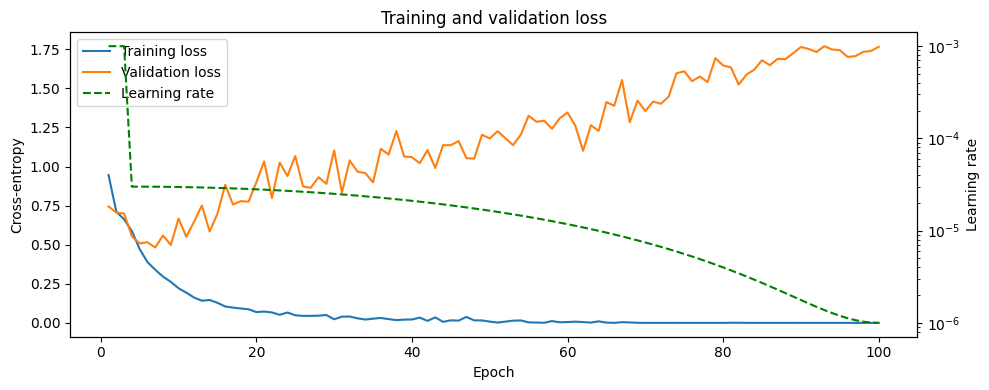

Completed 100 epochs. Selected epoch: 47 (highest validation accuracy). Final training/validation accuracy: 100.00%/82.68%. Final ten-epoch validation accuracy range: 0.67 percentage points; validation loss range: 0.0688. First two-rise/two-fall loss warning window: (11, 13). This is a descriptive warning, not proof of an exact overfitting onset. Low accuracy alone does not distinguish underfitting from limited generalization.


430

In [ ]:
import json, zipfile
import seaborn as sns
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
assert len(history) == EPOCHS

def save_figure(name):
    plt.savefig(OUT_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.epoch, history.loss, label='Training loss')
ax.plot(history.epoch, history.val_loss, label='Validation loss')
ax.set(xlabel='Epoch', ylabel='Cross-entropy', title='Training and validation loss')
ax2 = ax.twinx()
ax2.plot(history.epoch, history.learning_rate, '--', color='green', label='Learning rate')
ax2.set_yscale('log'); ax2.set_ylabel('Learning rate')
a, b = ax.get_legend_handles_labels(); c, d = ax2.get_legend_handles_labels()
ax.legend(a + c, b + d, loc='best')
fig.tight_layout(); save_figure('learning_curves.png')
tail = history.tail(10)
warning_windows = []
for i in range(2, len(history)):
    window = history.iloc[i-2:i+1]
    if window.phase.nunique() == 1 and (np.diff(window.val_loss) > 0).all() and (np.diff(window.loss) < 0).all():
        warning_windows.append((int(window.iloc[0].epoch), int(window.iloc[-1].epoch)))
analysis = (f"Completed {len(history)} epochs. Selected epoch: {best['epoch']} (highest validation accuracy). "
    f"Final training/validation accuracy: {history.iloc[-1].accuracy:.2%}/{history.iloc[-1].val_accuracy:.2%}. "
    f"Final ten-epoch validation accuracy range: {100 * (tail.val_accuracy.max()-tail.val_accuracy.min()):.2f} percentage points; "
    f"validation loss range: {tail.val_loss.max()-tail.val_loss.min():.4f}. "
    f"First two-rise/two-fall loss warning window: {warning_windows[0] if warning_windows else 'none'}. "
    "This is a descriptive warning, not proof of an exact overfitting onset. Low accuracy alone does not distinguish underfitting from limited generalization.")
print(analysis)
(OUT_DIR / 'curve_analysis.txt').write_text(analysis)

## 2.14–2.15 — Test results

The highest-validation-accuracy checkpoint has been restored. One prediction pass supplies every test metric and classification plot below. Test loss is ordinary one-hot cross-entropy. Balanced accuracy and macro F1 give each diagnosis equal weight; the confusion matrix is normalized by true-class row.

 1/48 ━━━━━━━━━━━━━━━━━━━━ 1:46 2s/step

 2/48 ━━━━━━━━━━━━━━━━━━━━ 8s 185ms/step

 3/48 ━━━━━━━━━━━━━━━━━━━━ 7s 164ms/step

 4/48 ━━━━━━━━━━━━━━━━━━━━ 6s 155ms/step

 5/48 ━━━━━━━━━━━━━━━━━━━━ 6s 150ms/step

 6/48 ━━━━━━━━━━━━━━━━━━━━ 6s 146ms/step

... (41 outputs left out)

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step

48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 182ms/step


test_accuracy           0.835762
test_loss               0.928612
balanced_accuracy       0.657277
macro_f1                0.678682
test_images          1510.000000
selected_epoch         47.000000
epochs_completed      100.000000
Name: result, dtype: float64

,precision,recall,f1-score,support
MEL,0.609375,0.487500,0.541667,160.000000
NV,0.887558,0.955357,0.920210,1008.000000
BCC,0.693333,0.722222,0.707483,72.000000
AKIEC,0.629630,0.653846,0.641509,52.000000
BKL,0.827338,0.628415,0.714286,183.000000
DF,0.636364,0.388889,0.482759,18.000000
VASC,0.722222,0.764706,0.742857,17.000000
accuracy,0.835762,0.835762,0.835762,0.835762
macro avg,0.715117,0.657277,0.678682,1510.000000
weighted avg,0.827784,0.835762,0.828191,1510.000000


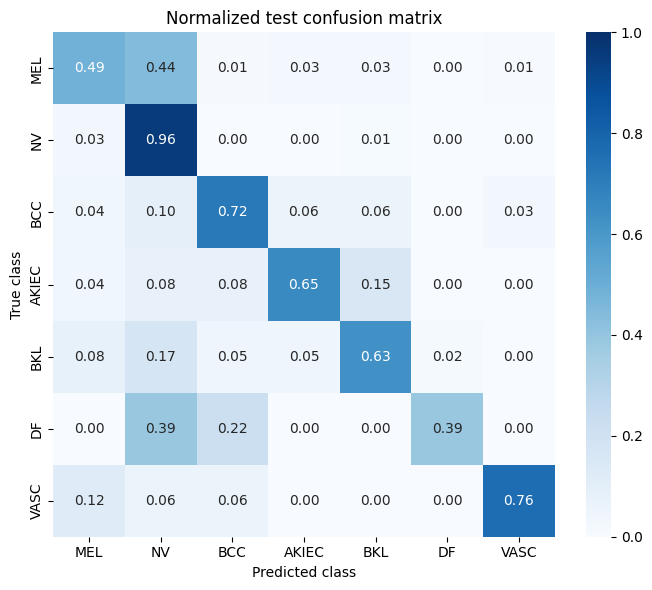

In [ ]:
test_ds = make_ds(test_df, training=False)
probabilities = model.predict(test_ds, verbose=1)
y_true = test_df.label.to_numpy(dtype=int)
y_pred = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
metrics = {
    'test_accuracy': float(accuracy_score(y_true, y_pred)),
    'test_loss': float(keras.losses.categorical_crossentropy(tf.one_hot(y_true, len(CLASS_NAMES)), probabilities).numpy().mean()),
    'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
    'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    'test_images': len(test_df), 'selected_epoch': int(best['epoch']), 'epochs_completed': len(history)
}
display(pd.Series(metrics, name='result'))
predictions = test_df[['image', 'lesion_id', 'filepath', 'label']].copy()
predictions['true_class'] = [CLASS_NAMES[i] for i in y_true]
predictions['predicted_class'] = [CLASS_NAMES[i] for i in y_pred]
predictions['confidence'] = confidence
for i, name in enumerate(CLASS_NAMES): predictions['p_' + name] = probabilities[:, i]
predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)
report = pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
report.to_csv(OUT_DIR / 'classification_report.csv'); display(report)
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
pd.DataFrame(cm_normalized, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUT_DIR / 'confusion_matrix.csv')
plt.figure(figsize=(7, 6))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title('Normalized test confusion matrix')
plt.tight_layout(); save_figure('confusion_matrix.png')

## 2.8–2.9 — Intermediate feature maps

The first test image is passed through the selected backbone to display 16 channels of `conv3_block4_out`. Strided convolutions reduce spatial size while deeper stages add channels for different features. Backpropagation updates trainable filters using loss gradients; frozen layers still transform their inputs.

Each channel is scaled separately for visibility. These maps show activations, not lesion masks or causal explanations.

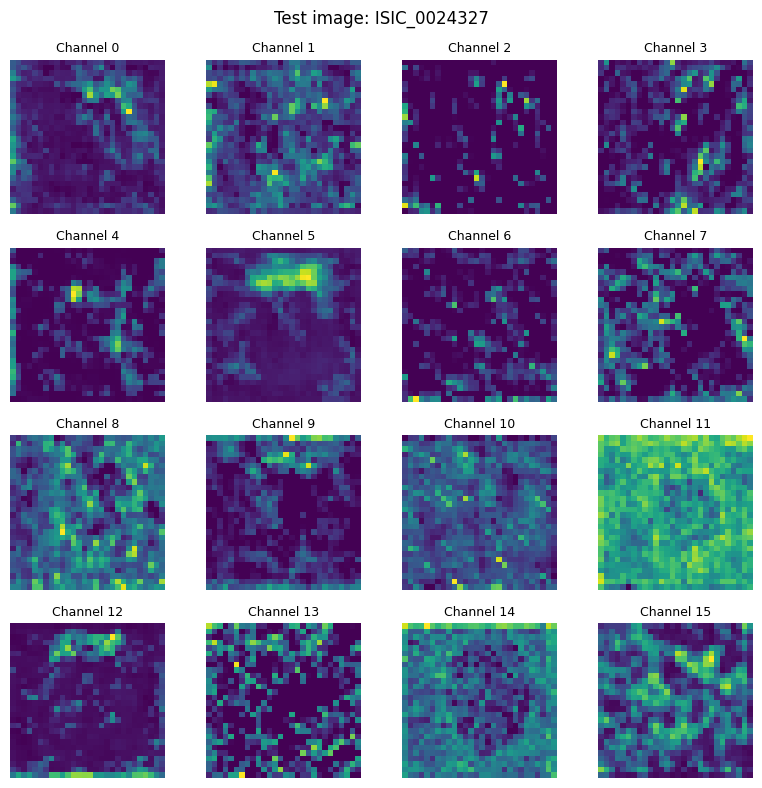

In [ ]:
first = test_df.iloc[0]
first_rgb = tf.cast(read_image(first.filepath)[None], tf.float32)
feature_model = keras.Model(backbone.input, backbone.get_layer('conv3_block4_out').output)
feature_input = keras.applications.resnet50.preprocess_input(first_rgb)
feature_maps = feature_model(feature_input, training=False).numpy()[0]
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    channel = feature_maps[:, :, i]
    ax.imshow((channel-channel.min()) / max(float(np.ptp(channel)), 1e-8), cmap='viridis')
    ax.set_title(f'Channel {i}', fontsize=9); ax.axis('off')
fig.suptitle('Test image: ' + str(first.image))
fig.tight_layout(); save_figure('feature_maps.png')

## 2.16–2.17 — Confident errors

All three examples were labelled MEL but predicted as NV: false positives for NV and false negatives for MEL. Their saved softmax confidence reached 100%, showing that high confidence does not guarantee correctness.

- **ISIC_0028760:** A compact lesion has a very dark upper region and a lighter brown lower extension. Its compact shape and brown pigmentation may resemble features associated with NV, despite the uneven pigmentation.
- **ISIC_0029209:** A small dark lesion occupies little of the frame, surrounded by pale, mottled skin and fine hairs. Resizing the whole image to 224 × 224 may make subtle boundary and texture details harder to distinguish.
- **ISIC_0030107:** The brown lesion has an uneven outline and darker central areas. Numerous hairs and bright circular artefacts overlap or surround it, potentially obscuring texture cues.

These are plausible explanations based on visible features; the images alone cannot establish what caused the model's decisions.

,image,true_class,predicted_class,confidence
663,ISIC_0028760,MEL,NV,1.0
731,ISIC_0029209,MEL,NV,1.0
865,ISIC_0030107,MEL,NV,1.0


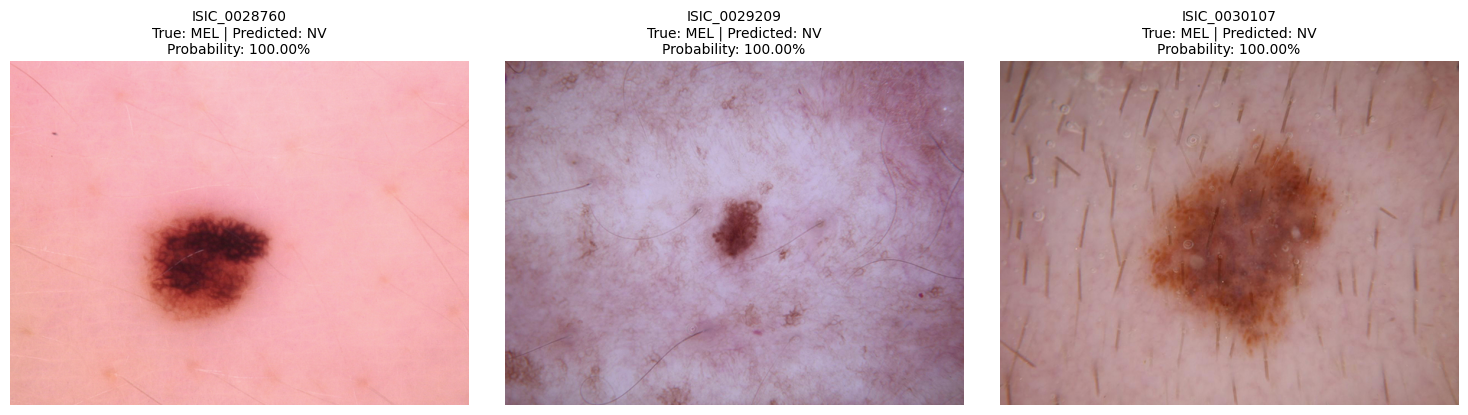

In [ ]:
errors = predictions[predictions.true_class != predictions.predicted_class].nlargest(3, 'confidence')
errors.to_csv(OUT_DIR / 'top3_errors.csv', index=False)
display(errors[['image', 'true_class', 'predicted_class', 'confidence']])
if len(errors):
    fig, axes = plt.subplots(1, len(errors), figsize=(5 * len(errors), 4), squeeze=False)
    for ax, (_, row) in zip(axes.flat, errors.iterrows()):
        ax.imshow(plt.imread(row.filepath))
        ax.set_title(f"{row.image}\nTrue: {row.true_class} | Predicted: {row.predicted_class}\nProbability: {row.confidence:.2%}", fontsize=10)
        ax.axis('off')
    fig.tight_layout(); save_figure('top3_errors.png')
else:
    print('No incorrect test predictions.')

## 2.18–2.19 — Unseen-image prediction

Test row 0 is selected independently of correctness and was excluded from training and checkpoint selection. Its horizontal bar chart uses the saved test probabilities.

The final Dense layer calculates logits $z$ and applies softmax: $p_k=\exp(z_k-m)/\sum_j\exp(z_j-m)$, where $m=\max_j z_j$. Subtracting the maximum prevents overflow. The probabilities sum to one. `predict_image(path)` applies the same resizing and model preprocessing to another image.

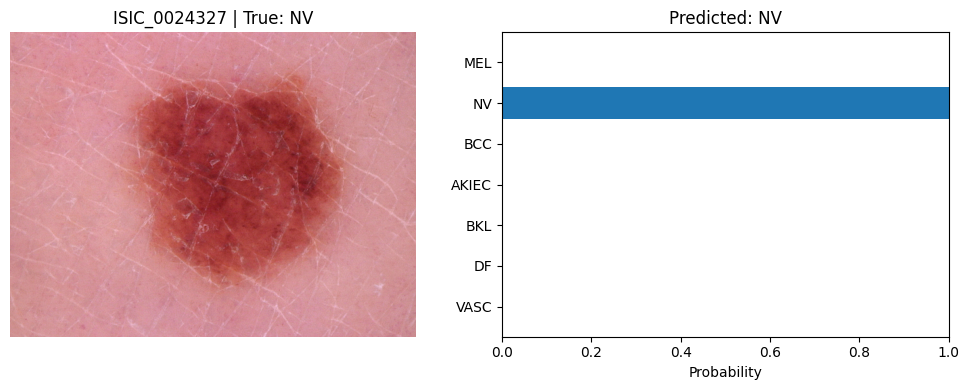

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(plt.imread(first.filepath))
axes[0].set_title(f'{first.image} | True: {CLASS_NAMES[y_true[0]]}'); axes[0].axis('off')
axes[1].barh(CLASS_NAMES, probabilities[0]); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Probability'); axes[1].set_title('Predicted: ' + CLASS_NAMES[y_pred[0]])
plt.tight_layout(); save_figure('unseen_image.png')

def predict_image(image_path):
    """Return class probabilities for a JPEG image."""
    rgb = tf.cast(read_image(image_path)[None], tf.float32)
    probs = model(rgb, training=False).numpy()[0]
    return pd.DataFrame({'class': CLASS_NAMES, 'probability': probs})
# Check that single-image preprocessing matches the saved test prediction.
np.testing.assert_allclose(predict_image(first.filepath)['probability'], probabilities[0], rtol=1e-3, atol=1e-5)
# Example: predict_image('/content/my_image.jpg')

## 2.20 — Confidence and calibration

Softmax can assign high confidence to an incorrect prediction. Cross-entropy, finite data and differences between training and new images can contribute to this behavior. A calibrated model is correct about 80% of the time among predictions assigned 80% confidence.

Ten confidence bins compare mean confidence with observed accuracy. ECE is their sample-weighted absolute difference. Its value depends on binning and sample counts; no calibration parameter is fitted on the test set.

For this run, mean test confidence was 95.48%, compared with 83.58% accuracy. The 10-bin ECE was 0.1194, indicating substantial overconfidence. No test-set calibration or further tuning was performed.

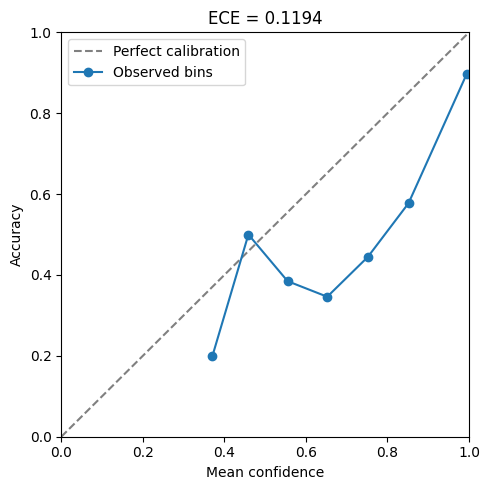

264

In [ ]:
bin_ids = np.minimum((confidence * 10).astype(int), 9)
rows = []
for b in range(10):
    mask = bin_ids == b
    if mask.any(): rows.append([int(mask.sum()), float(confidence[mask].mean()), float((y_pred[mask] == y_true[mask]).mean())])
calibration = pd.DataFrame(rows, columns=['count', 'confidence', 'accuracy'])
metrics['ece_10_bins'] = float((calibration['count'] / len(y_true) * abs(calibration.accuracy-calibration.confidence)).sum())
calibration.to_csv(OUT_DIR / 'calibration.csv', index=False)
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='grey', label='Perfect calibration')
plt.plot(calibration.confidence, calibration.accuracy, 'o-', label='Observed bins')
plt.xlabel('Mean confidence'); plt.ylabel('Accuracy'); plt.title(f"ECE = {metrics['ece_10_bins']:.4f}")
plt.xlim(0, 1); plt.ylim(0, 1); plt.legend(); plt.tight_layout(); save_figure('calibration.png')
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))

## Save results

The ZIP contains the selected weights, training history, test predictions, metrics and figures. Keep the executed notebook alongside it; `predict_image(path)` uses the selected model and the same image preprocessing as evaluation.

In [ ]:
history.to_csv(OUT_DIR / 'training_history.csv', index=False)
(OUT_DIR / 'class_mapping.json').write_text(json.dumps({'class_order': CLASS_NAMES}, indent=2))
archive_path = OUT_DIR.parent / 'isic2018_simple_results.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=3) as archive:
    for path in sorted(OUT_DIR.rglob('*')):
        if not path.is_file() or 'image_cache' in path.parts: continue
        if path.suffix not in {'.csv', '.json', '.txt', '.png', '.h5'}: continue
        if path.name.endswith('.weights.h5') and path.name != 'best_model.weights.h5': continue
        archive.write(path, arcname=path.relative_to(OUT_DIR))
print('Results saved to:', archive_path)

Results saved to: /Users/zhangfengrui/Documents/New projectdm/isic2018_part2/local_run/isic2018_simple_results.zip
